# 02 — Análise exploratória

**Enunciado etapa 2** \
Análise exploratória: calcule a proporção de cancelamentos e investigue sua
associação com o tempo de permanência, tipo de contrato, serviços contratados,
forma de pagamento e valores cobrados. Utilize gráficos e medidas descritivas,
considerando também o tamanho dos grupos comparados.

**Churn** \
0 : False \
1 : True

In [301]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Separação das colunas em grupos de variáveis

In [302]:
# Grupos de colunas
TARGET = "Churn"
NUMERIC_COLS = ["tenure", "MonthlyCharges", "TotalCharges"]
DEMOGRAPHIC_COLS = ["gender", "SeniorCitizen", "Partner", "Dependents"]
SERVICE_COLS = ["PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
CATEGORICAL_COLS = DEMOGRAPHIC_COLS + SERVICE_COLS + ["Contract", "PaperlessBilling", "PaymentMethod"]

**[IA]** - Aqui, utilizei IA para fazer funções reutilizáveis para exibir os gráficos e colunas do cruzamento entre o churn e as variáveis, a fim de evitar repetição de códigos grandes e deixar o notebook mais limpo

In [303]:
# Funções auxiliares da EDA
def churn_rate_table(df, col, sort=True):
    """Tamanho do grupo, nº de churns e taxa de churn com IC 95% (Wilson) por categoria de `col`."""
    tab = df.groupby(col, observed=True)[TARGET].agg(n="size", churn="sum")
    tab["taxa"] = tab["churn"] / tab["n"]
    z = 1.96
    centro = (tab["taxa"] + z**2 / (2 * tab["n"])) / (1 + z**2 / tab["n"])
    margem = z * np.sqrt(tab["taxa"] * (1 - tab["taxa"]) / tab["n"] + z**2 / (4 * tab["n"]**2)) / (1 + z**2 / tab["n"])
    tab["ic_inf"], tab["ic_sup"] = centro - margem, centro + margem
    return tab.sort_values("taxa", ascending=False) if sort else tab


def plot_churn_rate(tab, ax, title=None, overall=None, horizontal=False):
    """Barras da taxa de churn com IC 95% e o tamanho de cada grupo (n) sobre as barras."""
    x = np.arange(len(tab))
    erro = [tab["taxa"] - tab["ic_inf"], tab["ic_sup"] - tab["taxa"]]
    if horizontal:
        # Barras deitadas, com a primeira categoria no topo e o n à direita de cada barra
        ax.barh(x, tab["taxa"], xerr=erro, capsize=4, color="#DD8452")
        for xi, (sup, n) in enumerate(zip(tab["ic_sup"], tab["n"])):
            ax.text(sup + 0.01, xi, f"n={n}", va="center", fontsize=8)
        if overall is not None:
            ax.axvline(overall, color="gray", ls="--", lw=1, label=f"geral = {overall:.1%}")
            ax.legend(fontsize=8, loc="lower right")
        ax.set_yticks(x, tab.index.astype(str))
        ax.invert_yaxis()
        ax.set_xlim(0, tab["ic_sup"].max() * 1.2)
        ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
        ax.set(title=title or f"Taxa de churn por {tab.index.name}", xlabel="taxa de churn", ylabel="")
        return
    ax.bar(x, tab["taxa"], yerr=erro, capsize=4, color="#DD8452")
    for xi, (taxa, n) in enumerate(zip(tab["taxa"], tab["n"])):
        ax.text(xi, taxa / 2, f"n={n}", ha="center", fontsize=8, color="white")
    if overall is not None:
        ax.axhline(overall, color="gray", ls="--", lw=1, label=f"geral = {overall:.1%}")
        ax.legend(fontsize=8)
    ax.set_xticks(x, tab.index.astype(str))
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.set(title=title or f"Taxa de churn por {tab.index.name}", ylabel="taxa de churn", xlabel="")


Leitura do CSV da EDA

In [304]:
df = pd.read_csv("../data/processed/telco_eda.csv")
df[TARGET] = df[TARGET].map({"Yes": 1, "No": 0})
taxa_geral = df[TARGET].mean()
print(df.shape, f"taxa geral de churn = {taxa_geral:.1%}")

(7043, 21) taxa geral de churn = 26.5%


## 1. Proporção de cancelamentos

,n,proporção (%)
Churn,,
No,5174,73.463
Yes,1869,26.537


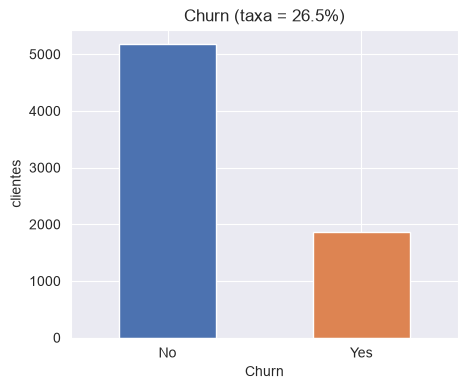

In [305]:
contagem = df[TARGET].value_counts().rename(index={0: "No", 1: "Yes"})
display(pd.DataFrame({"n": contagem, "proporção (%)": ((contagem / len(df))*100).round(3)}))

fig, ax = plt.subplots(figsize=(5, 4))
contagem.plot.bar(ax=ax, color=["#4C72B0", "#DD8452"], rot=0)
ax.set(title=f"Churn (taxa = {taxa_geral:.1%})", ylabel="clientes")
plt.show()

A base é desbalanceada, com taxa de churn de 26.5%. Essa é a linha de referência (tracejada) dos gráficos seguintes. Um grupo só merecerá destaque se a taxa dele com o IC, ficar claramente acima ou abaixo dela.

Um modelo que sempre prevê "não churn" acertará 73%

## 2. `tenure` - Tempo de permanência

In [306]:
df.groupby(TARGET)["tenure"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
0,5174.0,37.6,24.1,0.0,15.0,38.0,61.0,72.0
1,1869.0,18.0,19.5,1.0,2.0,10.0,29.0,72.0


Para cruzar `tenure` (numérica) com o `Churn`, discretizei a variável em 7 faixas com `pd.cut`: \
["0-3","4-6", "7-12", "13-24", "25-36", "37-48", "49-60", "61-72"]  \
Essas faixas foram escolhidas para separar os primeiros meses, depois ano por ano

,n,churn,taxa,ic_inf,ic_sup
tenure_faixa,,,,,
0-3,1062,597,0.562,0.532,0.592
4-6,419,187,0.446,0.399,0.494
7-12,705,253,0.359,0.324,0.395
13-24,1024,294,0.287,0.260,0.316
25-36,832,180,0.216,0.190,0.246
37-48,762,145,0.190,0.164,0.220
49-60,832,120,0.144,0.122,0.170
61-72,1407,93,0.066,0.054,0.080


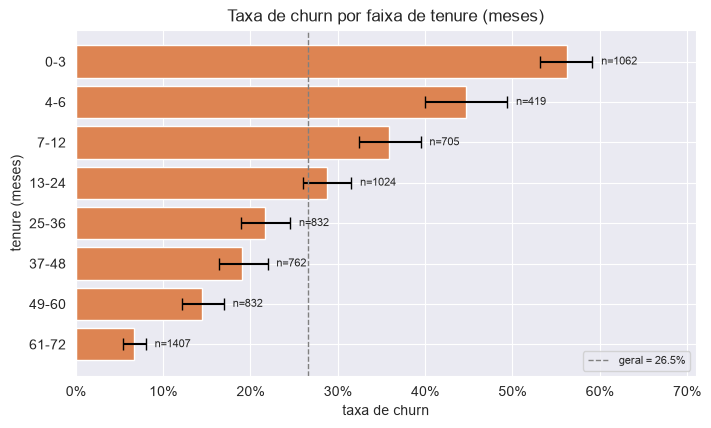

In [307]:
df["tenure_faixa"] = pd.cut(df["tenure"], bins=[-1, 3, 6, 12, 24, 36, 48, 60, 72],
                            labels=["0-3", "4-6", "7-12", "13-24", "25-36", "37-48", "49-60", "61-72"])
tab = churn_rate_table(df, "tenure_faixa", sort=False)
display(tab.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
plot_churn_rate(tab, ax=ax, title="Taxa de churn por faixa de tenure (meses)", overall=taxa_geral, horizontal=True)
ax.set_ylabel("tenure (meses)")
plt.show()

Note-se que a taxa de churn é muito alta nos primeiros meses

## 3. Tipo de contrato

,n,churn,taxa,ic_inf,ic_sup
Contract,,,,,
Month-to-month,3875,1655,0.427,0.412,0.443
One year,1473,166,0.113,0.098,0.130
Two year,1695,48,0.028,0.021,0.037


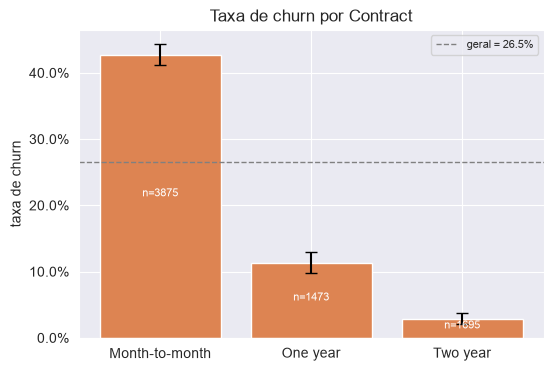

In [308]:
tab = churn_rate_table(df, "Contract")
display(tab.round(3))
fig, ax = plt.subplots(figsize=(6, 4))
plot_churn_rate(tab, ax=ax, overall=taxa_geral)
plt.show()

Contratos de mensalidade concentram alta taxa de Churn

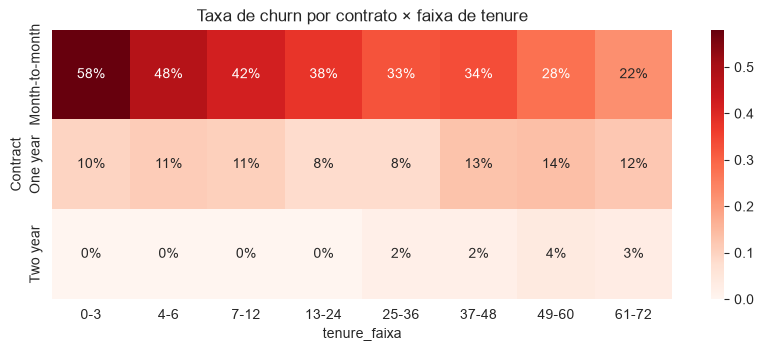

tenure_faixa,0-3,4-6,7-12,13-24,25-36,37-48,49-60,61-72
Contract,,,,,,,,
Month-to-month,1025,388,581,737,486,316,234,108
One year,21,18,85,197,250,268,321,313
Two year,16,13,39,90,96,178,277,986


In [309]:
# Relação entre Contrato e tenure x Churn
pivot = df.pivot_table(index="Contract", columns="tenure_faixa", values=TARGET, aggfunc="mean", observed=True)
tamanhos = df.pivot_table(index="Contract", columns="tenure_faixa", values=TARGET, aggfunc="size", observed=True)
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Reds", ax=ax)
ax.set_title("Taxa de churn por contrato × faixa de tenure")
plt.show()
tamanhos  # tamanho de cada célula — cuidado com células pequenas!

* Apesar do contrato `Month-to-month` ter taxa muito alta de Churn, para essa categoria, quanto mais tempo o cliente passa com o serviço, menos ele tende a dar Churn
* Já para as categorias `One year` e `Two year` as taxas de Churn são bem baixas, mas a partir de 2 a 3 anos de uso do serviço, a taxa de Churn tende a aumentar comparado com o período inicial.

## 4. Serviços contratados

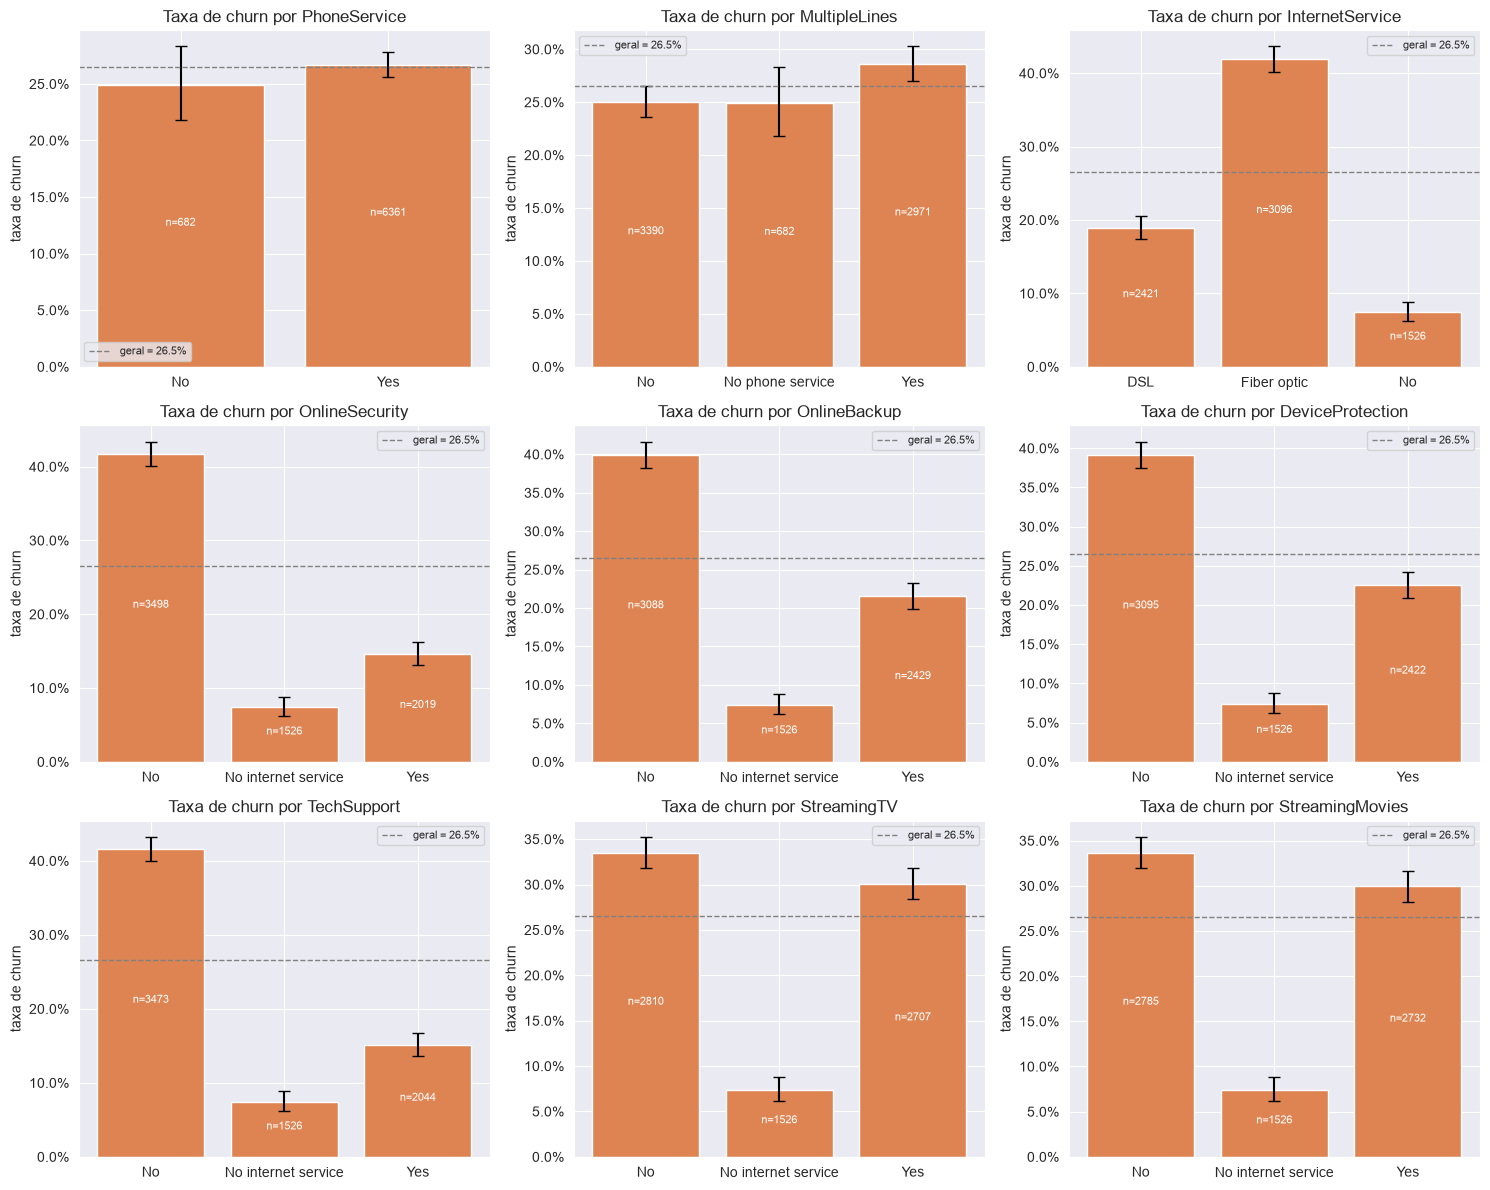

In [310]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for col, ax in zip(SERVICE_COLS, axes.ravel()):
    plot_churn_rate(churn_rate_table(df, col, sort=False), ax=ax, overall=taxa_geral)
fig.tight_layout()
plt.show()

* A maior diferença da taxa de Churn está concentrada principalmente em:
    * InternetService - Fiber optic
    * OnlineSecurity - No
    * OnlineBackup - No
    * DeviceProtection - No
    * TechSupport - No

Essas variáveis parecem ter grande poder para ditar a probabilidade de Churn

## 5. Forma de pagamento

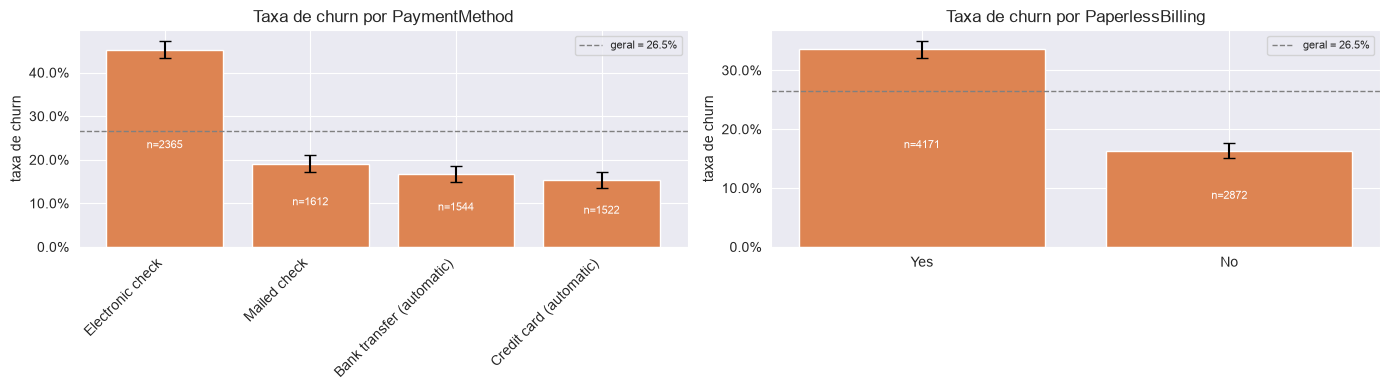

,n,churn,taxa,ic_inf,ic_sup
PaymentMethod,,,,,
Electronic check,2365,1071,0.453,0.433,0.473
Mailed check,1612,308,0.191,0.173,0.211
Bank transfer (automatic),1544,258,0.167,0.149,0.187
Credit card (automatic),1522,232,0.152,0.135,0.171


In [311]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for col, ax in zip(["PaymentMethod", "PaperlessBilling"], axes):
    plot_churn_rate(churn_rate_table(df, col), ax=ax, overall=taxa_geral)
plt.setp(axes[0].get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
plt.show()
churn_rate_table(df, "PaymentMethod").round(3)

* Electronic check e PaperlessBilling = Yes se destacam pela maior taxa de Churn

## 6. Valores cobrados

In [312]:
df.groupby(TARGET)[["MonthlyCharges", "TotalCharges"]].describe().T.round(1)

Churn                      0       1
MonthlyCharges count  5174.0  1869.0
               mean     61.3    74.4
               std      31.1    24.7
               min      18.2    18.8
               25%      25.1    56.2
               50%      64.4    79.6
               75%      88.4    94.2
               max     118.8   118.4
TotalCharges   count  5174.0  1869.0
               mean   2549.9  1531.8
               std    2330.0  1890.8
               min       0.0    18.8
               25%     572.9   134.5
               50%    1679.5   703.6
               75%    4262.8  2331.3
               max    8672.4  8684.8

Para o cruzamento da taxa de Churn com MonthlyCharges e TotalCharges, dividi-as em faixas com quantidades aproximadas de observações em cada faixa, usando `qcut`

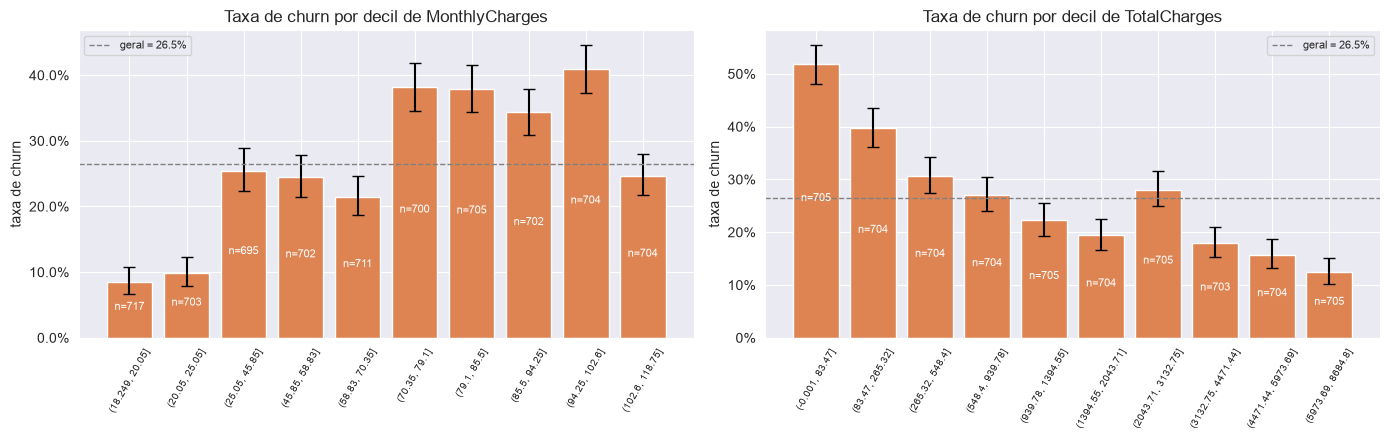

In [313]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for col, ax in zip(["MonthlyCharges", "TotalCharges"], axes):
    tab = churn_rate_table(df.assign(faixa=pd.qcut(df[col], q=10)), "faixa", sort=False)
    plot_churn_rate(tab, ax=ax, title=f"Taxa de churn por decil de {col}", overall=taxa_geral)
    ax.tick_params(axis="x", rotation=60, labelsize=7)
fig.tight_layout()
plt.show()

* O gráfico de MonthlyCharges x Churn indica que há churn mais alto nos planos mais caros. Isso pode indicar um problema de custo-benefício nesses planos. Nos planos de valor mais alto da tabela o churn volta a cair, possivelmente por contratos longos ou pacotes completos.
* O gráfico de TotalCharges x Churn mostra uma relação inversa ao observado em MonthlyCharges, valor mais baixos concentram mais Churn, e os mais altos menos. Isso faz sentido, pois TotalCharges menores indicam clientes mais novos, e esses são os que mais tendem a dar Churn, como observado na análise da variável `tenure`

## 7. Variáveis demográficas

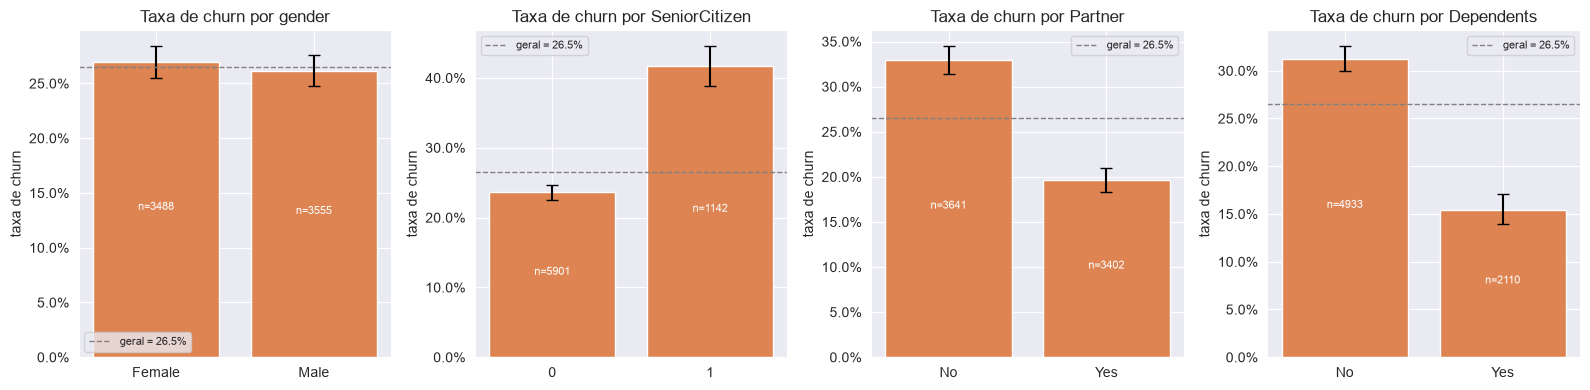

In [314]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for col, ax in zip(DEMOGRAPHIC_COLS, axes):
    plot_churn_rate(churn_rate_table(df, col, sort=False), ax=ax, overall=taxa_geral)
fig.tight_layout()
plt.show()

* O gênero do cliente não tem associação com churn, ambas os nº de amostras em cada categoria, e suas taxas de Churn são bem semelhantes
* SeniorCitizen = 1 se destaca por ter maior taxa de Churn, porém é uma categoria com quantidade de observações baixa, comparada a SeniorCitizen = 0
* Clientes sem parceiro(a) e sem dependentes cancelam mais

## Conclusões da EDA

**Características estão associadas a maiores taxas de cancelamento** (taxa geral = 26,5%)

| Característica | Taxa de churn | n |
|---|---|---|
| Tenure 0-3 meses | 56,2% | 1062 |
| Electronic check | 45,3% | 2365 |
| Month-to-month | 42,7% | 3875 |
| Fiber optic | 41,9% | 3096 |
| Sem OnlineSecurity / TechSupport | ~42% | ~3500 |
| SeniorCitizen | 41,7% | 1142 |
| PaperlessBilling | 33,6% | 4171 |

O perfil de maior risco é o cliente **novo, com contrato mensal, fibra óptica sem serviços de suporte/segurança, com método de pagamento `Electronic check`**.

**Como tenure, contrato e valores cobrados se relacionam com o cancelamento?**
* **Tenure:** relação forte e decrescente. O risco se concentra no primeiro ano
* **Contrato:** é a variável mais discriminante (42,7% / 11,3% / 2,8%)
* **Valores:** MonthlyCharges alto se associa a mais churn. TotalCharges baixo se associa a mais churn porque reflete tenure baixo

**Ressalvas**
* Tudo aqui é associação, e não causalidade
* Grupos pequenos (ex.: células de contrato longo com tenure baixo, n < 40) devem ser interpretados com cautela
* Variáveis com pouco poder de separação (`gender`, `PhoneService`, `MultipleLines`, streaming) são candidatas a ter pouco peso no modelo